<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5d_dualcomplexos_perseguicao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V (d): Pepé inteiro, num número só

## Pepé estima a própria pose (posição e nariz) e a de Penélope: radar polar, odometria e três maneiras de definir o erro

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 5](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb)) · **Anterior:** [X5c_dualcomplexos_edo.ipynb](X5c_dualcomplexos_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5c_dualcomplexos_edo.ipynb))

**A história.** No domínio IV, Pepé sabia onde estava (um GPS perfeito) e só a orientação era incerta. Agora ele não sabe nem uma coisa nem outra: a **pose** dele, posição e nariz, é um dual-complexo $q$ a estimar. Ele tem:
- **odometria:** a velocidade de avanço (pelas rodas) e a de giro (por um giroscópio), com ruído;
- **um radar** que gira, e mede a **distância** e a **direção** (em relação ao nariz) de cada coisa à volta: os quatro faróis, em posições conhecidas, e Penélope. É um sensor **polar**: a medida é $(\lvert m\rvert,\arg m)$, com $m=e^{-i\theta}(w-p)$ o ponto $w$ visto do referencial de Pepé.

O filtro estima, ao mesmo tempo, a pose de Pepé e a posição e a velocidade de Penélope. A pose não é um vetor, e o filtro guarda a covariância de um **erro** de três componentes. Como $SE(2)$ não é comutativo, há mais de uma maneira de definir esse erro (notebook V(c), seção 5), e este notebook compara três:
1. **EKF nas coordenadas** $(x,y,\theta)$, como se a pose fosse um vetor;
2. **erro no corpo:** $q=\hat q\,\mathrm{Exp}(\xi)$;
3. **erro no mundo:** $q=\mathrm{Exp}(\xi)\,\hat q$, o filtro de Kalman estendido **invariante** de Barrau e Bonnabel para este problema.

**O que este notebook mostra.**
1. Com os faróis, os três filtros têm praticamente a mesma precisão, **desde que a predição use a $\mathrm{Exp}$ do grupo** (o arco). O EKF nas coordenadas escrito do jeito habitual, com o passo de Euler (um segmento de reta), fica otimista: a covariância promete mais do que o filtro entrega.
2. Quando o sensor de referência é um **GPS** (que mede a posição de Pepé, e não a direção) e Pepé começa sem saber para onde está virado, o par "erro" e "sensor" importa: o erro no corpo combina com o GPS, e o filtro com erro no mundo fica inconsistente nos primeiros segundos.
3. Com qualquer filtro bom, Pepé persegue Penélope como no domínio IV.

**Roteiro**
1. O mundo e os sensores
2. Os três filtros: predição, correção e reinício
3. Faróis e radar: os três erros, e o modelo de Euler
4. GPS e um Pepé desorientado: o erro certo para o sensor certo
5. O que levar deste notebook
6. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import pandas as pd
from scipy.linalg import expm
N_MC = 20            # simulações de Monte Carlo por configuração (~1 min no total)

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

class DC:
    """Número dual-complexo q = a + b·ε, com a = a0 + i·a1 e b = b0 + i·b1, e a regra z·ε = ε·z̄.
    Guardado como quatro reais (a0, a1, b0, b1), que podem ser floats, Fractions ou números duais."""
    def __init__(self, a0, a1, b0, b1):
        self.a0, self.a1, self.b0, self.b1 = a0, a1, b0, b1
    def __mul__(self, o):
        if not isinstance(o, DC):                       # número real vezes dual-complexo
            return DC(self.a0 * o, self.a1 * o, self.b0 * o, self.b1 * o)
        # a = a1·a2 ;  b = a1·b2 + b1·conj(a2)   (a regra z ε = ε z̄ conjuga o fator que "passa" por ε)
        a0 = self.a0 * o.a0 - self.a1 * o.a1
        a1 = self.a0 * o.a1 + self.a1 * o.a0
        b0 = (self.a0 * o.b0 - self.a1 * o.b1) + (self.b0 * o.a0 + self.b1 * o.a1)
        b1 = (self.a0 * o.b1 + self.a1 * o.b0) + (self.b1 * o.a0 - self.b0 * o.a1)
        return DC(a0, a1, b0, b1)
    __rmul__ = __mul__
    def __add__(self, o): return DC(self.a0 + o.a0, self.a1 + o.a1, self.b0 + o.b0, self.b1 + o.b1)
    def __sub__(self, o): return DC(self.a0 - o.a0, self.a1 - o.a1, self.b0 - o.b0, self.b1 - o.b1)
    def conj(self):
        """q* = ā − b ε: o inverso de um dual-complexo unitário."""
        return DC(self.a0, -self.a1, -self.b0, -self.b1)
    def norma2(self):
        """q q* = |a|² (um número real: a parte dual se cancela)."""
        return self.a0 * self.a0 + self.a1 * self.a1
    @property
    def a(self): return complex(self.a0, self.a1)
    @property
    def b(self): return complex(self.b0, self.b1)
    def __repr__(self): return f"({self.a:.6g}) + ({self.b:.6g})ε"

def pose(theta, t):
    """A pose 'girar θ, transladar t' (t complexo): q = r + (t r̄ / 2) ε, com r = e^{iθ/2}."""
    r = np.exp(0.5j * theta); b = t * np.conj(r) / 2
    return DC(r.real, r.imag, b.real, b.imag)

def angulo(q):
    return float(wrap(2 * np.arctan2(q.a1, q.a0)))

def translacao(q):
    """t = 2 b a / |a|² (vale também para q não unitário)."""
    return 2 * q.b * q.a / q.norma2()

def aplica(q, p):
    """O ponto p (complexo) levado pela pose q: a translação de q · (translação até p)."""
    return translacao(q * pose(0.0, p))

def Exp(w, v):
    """Velocidade (ω, v) no corpo, v complexo, por uma unidade de tempo: um arco de círculo (ou um segmento, se ω = 0)."""
    return pose(w, v * np.exp(0.5j * w) * sinc(w / 2))

def Log(q):
    th = angulo(q)
    return th, translacao(q) / (np.exp(0.5j * th) * sinc(th / 2))


def Ad(q):
    th, t = angulo(q), translacao(q); c_, s_ = np.cos(th), np.sin(th)
    return np.array([[1, 0, 0], [t.imag, c_, -s_], [-t.real, s_, c_]])
def Log3(q):
    w, v = Log(q); return np.array([w, v.real, v.imag])
def Exp3(xi):
    return Exp(xi[0], xi[1] + 1j * xi[2])

---

## 1. O mundo e os sensores

**A arena e Penélope** são as dos domínios II e IV. **Pepé** anda como no domínio IV (para a frente, até 2,5 m/s, girando até 2 rad/s), comandado pelas **estimativas**: a da própria pose e a de Penélope. Se a incerteza sobre Penélope fica grande, ele gira no lugar procurando-a. A pose verdadeira de Pepé avança pela $\mathrm{Exp}$ do grupo: $q\leftarrow q\,\mathrm{Exp}(\omega\Delta t,\ v\Delta t)$, um arco de círculo a cada passo.

**A odometria** mede, a 20 Hz, $v+n_v$ e $\omega+n_\omega$, com ruídos de 0,1 m/s e 0,05 rad/s por amostra.

**O radar** mede, a 10 Hz, a distância e a direção de cada faról e de Penélope, com ruídos de 0,3 m e 2°:
$$m=e^{-i\theta}(w-p),\qquad\mathbf z=\big(\lvert m\rvert+n_r,\ \arg m+n_\beta\big).$$
É um sensor não linear duas vezes: a rotação para o referencial de Pepé, e a passagem para coordenadas polares. Os faróis estão em $20-10i$, $50+20i$, $20+50i$ e $-10+20i$.

**O jacobiano polar.** Se $m$ muda de $\delta m$, então $\delta\lvert m\rvert=\operatorname{Re}(\bar m\,\delta m)/\lvert m\rvert$ e $\delta\arg m=\operatorname{Im}(\bar m\,\delta m)/\lvert m\rvert^2$. Basta, então, saber como $m$ muda com cada componente do erro (a seção 2), e a passagem para o radar é a mesma para os três filtros.

In [2]:
DT, T_FIM, L = 0.05, 60.0, 40.0
SIG_F, TAU_F, F_FUGA, R_FUGA, K_PAREDE = 2.0, 1.5, 3.0, 8.0, 50.0
V_P, W_MAX, GANHO_W, GANHO_V = 2.5, 2.0, 3.0, 1.5
FAROIS = np.array([20 - 10j, 50 + 20j, 20 + 50j, -10 + 20j])
SIG_V, SIG_W = 0.1, 0.05
SIG_R, SIG_B = 0.3, np.radians(2.0)
SIG_GPS = 0.3
INICIO_A, INICIO_P = 28 + 20j, 12 + 20j

def discretiza(A, B, dt, q=None):
    n, m = A.shape[0], B.shape[1]
    Maug = np.zeros((n + m, n + m)); Maug[:n, :n] = A; Maug[:n, n:] = B
    E = expm(Maug * dt); F, G = E[:n, :n], E[:n, n:]
    if q is None:
        return F, G
    V = np.zeros((2 * n, 2 * n)); V[:n, :n] = -A; V[:n, n:] = B @ np.diag(q) @ B.T; V[n:, n:] = A.T
    W = expm(V * dt); Q = F @ W[:n, n:]
    return F, G, 0.5 * (Q + Q.T)

Z2, I2 = np.zeros((2, 2)), np.eye(2)
F_PEN, G_PEN = discretiza(np.block([[Z2, I2], [Z2, -I2]]), np.vstack([Z2, I2]), DT)
F_CV, _, Q_CV = discretiza(np.block([[Z2, I2], [Z2, Z2]]), np.vstack([Z2, I2]), DT, [1.0, 1.0])
c2v = lambda z: np.array([z.real, z.imag]); v2c = lambda v: v[0] + 1j * v[1]

def forca_penelope(a, p, f_al):
    d = a - p; r = abs(d)
    fuga = F_FUGA * (d / r if r > 1e-9 else 0) * max(0.0, 1 - r / R_FUGA)
    parede = -K_PAREDE * (min(a.real, 0) + max(a.real - L, 0)) - 1j * K_PAREDE * (min(a.imag, 0) + max(a.imag - L, 0))
    return f_al + fuga + parede

def linha_polar(m, dm):
    """Derivadas de (|m|, arg m) quando m muda de dm (complexo)."""
    return np.array([(np.conj(m) * dm).real / abs(m), (np.conj(m) * dm).imag / abs(m)**2])

m_t, dm_t, h = 3 + 4j, 0.2 - 0.7j, 1e-7
num = (np.array([abs(m_t + h * dm_t), np.angle(m_t + h * dm_t)]) - np.array([abs(m_t - h * dm_t), np.angle(m_t - h * dm_t)])) / (2 * h)
confere("jacobiano polar = diferenças finitas", linha_polar(m_t, dm_t), num, tol=1e-8)

OK   jacobiano polar = diferenças finitas:  diferença máxima = 8.79e-10


---

## 2. Os três filtros

O estado de erro tem sete componentes: três da pose de Pepé e quatro de Penélope (posição e velocidade, com o erro aditivo de sempre). Os três filtros diferem só nas três primeiras.

**Como $m=e^{-i\theta}(w-p)$ muda com o erro da pose** (deduzido em primeira ordem, com $\hat m$ a medida prevista):

| filtro | erro | $\delta m$ |
|---|---|---|
| coordenadas | $\theta=\hat\theta+\delta\theta$, $p=\hat p+\delta p$ | $-i\hat m\,\delta\theta-e^{-i\hat\theta}\,\delta p$ |
| no corpo | $q=\hat q\,\mathrm{Exp}(\xi)$, $\xi=(\delta\theta,\delta v)$ | $-i\hat m\,\delta\theta-\delta v$ |
| no mundo | $q=\mathrm{Exp}(\xi)\,\hat q$, $\xi=(\delta\theta,\delta v)$ | $-e^{-i\hat\theta}\big(\delta v+i\,\delta\theta\,w\big)$ |

E, para Penélope, $\delta m$ ganha $+e^{-i\hat\theta}\delta a$ nos três. Repare na última linha: com o erro no mundo, a derivada não depende da posição estimada de Pepé, só da posição $w$ do que se mede (e de uma rotação). É a propriedade de **invariância**.

**Predição da pose e do erro** (notebook V(c), seção 5):
- coordenadas: $\hat\theta\leftarrow\hat\theta+\omega\Delta t$, $\hat p\leftarrow\hat p+v\Delta t\,e^{i\hat\theta}$ (Euler, o jeito habitual), ou o arco da $\mathrm{Exp}$ (a opção `arco`); a matriz $\mathbf F$ é o jacobiano dessa conta;
- no corpo: $\hat q\leftarrow\hat q\,\mathrm{Exp}(u)$, $\mathbf F=\mathrm{Ad}_{\mathrm{Exp}(-u)}$;
- no mundo: $\hat q\leftarrow\hat q\,\mathrm{Exp}(u)$, $\mathbf F=\mathbf I$, ruído levado ao mundo por $\mathrm{Ad}_{\hat q}$.

**Reinício.** Depois de cada correção, o erro estimado $\delta\hat\xi$ é aplicado à pose (por soma, por $\hat q\,\mathrm{Exp}(\delta\hat\xi)$ ou por $\mathrm{Exp}(\delta\hat\xi)\,\hat q$) e volta a zero.

**A crença inicial** é a mesma para os três: posição com desvio de 1 m e ângulo com desvio $\sigma_{\theta,0}$, gaussianos nas coordenadas. Para os filtros com erro no grupo, essa covariância é levada ao respectivo erro pela relação linear entre os erros: no corpo, $\delta v=e^{-i\hat\theta}\delta p$; no mundo, $\delta v=\delta p-i\,\delta\theta\,\hat p$. (Esquecer essa conversão foi o erro do filtro com quaternions "ingênuo" do notebook 6 da série Kalman.)

In [3]:
def simula(cfg, seed):
    """cfg: tipo ('coord', 'corpo', 'mundo'), arco (só coord), sensores ('farois' ou 'gps'), sig_th0."""
    rng = np.random.default_rng(seed)
    tipo, sig0 = cfg["tipo"], cfg.get("sig_th0", 0.1)
    a, va, f_al = INICIO_A, 0j, 0j
    q = pose(0.0, INICIO_P)
    qh = pose(rng.normal(0, sig0), INICIO_P + complex(*rng.normal(0, 1.0, 2)))
    xa = np.r_[c2v(INICIO_A + 3 * complex(*rng.standard_normal(2))), 0.0, 0.0]
    P = np.zeros((7, 7)); P[0, 0] = sig0**2; P[1:3, 1:3] = I2; P[3:, 3:] = np.diag([9, 9, 4, 4.0])
    th0, p0 = angulo(qh), translacao(qh)
    J0 = np.eye(3)
    if tipo == "corpo":
        J0[1:, 1:] = [[np.cos(th0), np.sin(th0)], [-np.sin(th0), np.cos(th0)]]
    elif tipo == "mundo":
        J0[1, 0], J0[2, 0] = p0.imag, -p0.real
    P[:3, :3] = J0 @ P[:3, :3] @ J0.T
    reg = {k: [] for k in ["a", "p", "a_est", "e_pos", "e_th", "nees"]}

    def aplica_correcao(dx):
        nonlocal qh, xa
        xa = xa + dx[3:]
        if tipo == "coord":
            qh = pose(angulo(qh) + dx[0], translacao(qh) + v2c(dx[1:3]))
        elif tipo == "corpo":
            qh = qh * Exp3(dx[:3])
        else:
            qh = Exp3(dx[:3]) * qh

    for k in range(int(T_FIM / DT)):
        # mundo
        f_al = f_al - f_al / TAU_F * DT + SIG_F * np.sqrt(2 * DT / TAU_F) * complex(*rng.standard_normal(2))
        y = F_PEN @ np.r_[c2v(a), c2v(va)] + G_PEN @ c2v(forca_penelope(a, translacao(q), f_al))
        a, va = v2c(y[:2]), v2c(y[2:])
        th_h, p_h = angulo(qh), translacao(qh)
        alvo = v2c(xa[:2]); e = np.angle(np.exp(-1j * th_h) * (alvo - p_h))
        w_cmd = np.clip(GANHO_W * e, -W_MAX, W_MAX); v_cmd = np.clip(GANHO_V * abs(alvo - p_h) * max(np.cos(e), 0), 0, V_P)
        if np.trace(P[3:5, 3:5]) > 16:
            w_cmd, v_cmd = W_MAX, 0.0
        q = q * Exp(w_cmd * DT, v_cmd * DT + 0j)
        v_m, w_m = v_cmd + SIG_V * rng.standard_normal(), w_cmd + SIG_W * rng.standard_normal()
        # predição
        u = np.array([w_m * DT, v_m * DT, 0.0])
        Qb = np.diag([(SIG_W * DT)**2, (SIG_V * DT)**2, (0.02 * DT)**2])
        F = np.eye(7); Q = np.zeros((7, 7))
        if tipo == "coord":
            th = angulo(qh)
            F[1:3, 0] = c2v(1j * v_m * np.exp(1j * th) * DT)
            Rm = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
            G = np.eye(3); G[1:, 1:] = Rm
            Q[:3, :3] = G @ Qb @ G.T
            qh = qh * Exp3(u) if cfg.get("arco", False) else pose(th + w_m * DT, translacao(qh) + v_m * DT * np.exp(1j * th))
        elif tipo == "corpo":
            Eu = Exp3(u); F[:3, :3] = Ad(Eu.conj()); Q[:3, :3] = Qb
            qh = qh * Eu
        else:
            qh = qh * Exp3(u); A = Ad(qh); Q[:3, :3] = A @ Qb @ A.T
        F[3:, 3:] = F_CV; Q[3:, 3:] = Q_CV
        xa = F_CV @ xa
        P = F @ P @ F.T + Q
        # correção a 10 Hz
        if k % 2 == 1:
            if cfg.get("sensores", "farois") == "gps":
                z = c2v(translacao(q)) + SIG_GPS * rng.standard_normal(2)
                th_h, p_h = angulo(qh), translacao(qh)
                H = np.zeros((2, 7))
                if tipo == "coord":
                    H[:, 1:3] = I2
                elif tipo == "corpo":
                    H[:, 1:3] = [[np.cos(th_h), -np.sin(th_h)], [np.sin(th_h), np.cos(th_h)]]
                else:
                    H[:, 0] = [-p_h.imag, p_h.real]; H[:, 1:3] = I2
                S = H @ P @ H.T + SIG_GPS**2 * I2; K = np.linalg.solve(S, H @ P).T
                dx = K @ (z - c2v(p_h)); P = P - K @ S @ K.T; P = 0.5 * (P + P.T)
                aplica_correcao(dx)
            alvos = ([("farol", f) for f in FAROIS] if cfg.get("sensores", "farois") == "farois" else []) + [("Penélope", a)]
            for tipo_alvo, w in alvos:
                m_ver = np.exp(-1j * angulo(q)) * (w - translacao(q))
                z = np.array([abs(m_ver) + SIG_R * rng.standard_normal(), np.angle(m_ver) + SIG_B * rng.standard_normal()])
                th_h, p_h = angulo(qh), translacao(qh)
                w_h = v2c(xa[:2]) if tipo_alvo == "Penélope" else w
                m = np.exp(-1j * th_h) * (w_h - p_h); R_ = np.exp(-1j * th_h)
                if tipo == "coord":   dms = [-1j * m, -R_, -R_ * 1j]
                elif tipo == "corpo": dms = [-1j * m, -1 + 0j, -1j]
                else:                 dms = [-R_ * 1j * w_h, -R_, -R_ * 1j]
                dms += [R_, R_ * 1j] if tipo_alvo == "Penélope" else [0j, 0j]
                H = np.zeros((2, 7)); H[:, :5] = np.column_stack([linha_polar(m, dm) for dm in dms])
                nu = z - np.array([abs(m), np.angle(m)]); nu[1] = wrap(nu[1])
                S = H @ P @ H.T + np.diag([SIG_R**2, SIG_B**2]); K = np.linalg.solve(S, H @ P).T
                dx = K @ nu; P = P - K @ S @ K.T; P = 0.5 * (P + P.T)
                aplica_correcao(dx)
        # registro: o erro verdadeiro, medido nas coordenadas do próprio filtro
        if tipo == "coord":
            ep = np.array([wrap(angulo(q) - angulo(qh)), *c2v(translacao(q) - translacao(qh))])
        elif tipo == "corpo":
            ep = Log3(qh.conj() * q)
        else:
            ep = Log3(q * qh.conj())
        for nome, val in zip(reg, [a, translacao(q), v2c(xa[:2]), abs(translacao(q) - translacao(qh)),
                                   abs(wrap(angulo(q) - angulo(qh))), ep @ np.linalg.solve(P[:3, :3], ep)]):
            reg[nome].append(val)
    return {k: np.array(v) for k, v in reg.items()}

def metricas(h):
    e = np.abs(h["a"] - h["a_est"]); d = np.abs(h["a"] - h["p"]); k0 = int(5 / DT)
    return {"perdeu o rastro": bool((e[-int(10 / DT):] > 5).mean() > 0.9),
            "erro de posição de Pepé (cm)": 100 * np.median(h["e_pos"][k0:]),
            "erro de direção de Pepé (graus)": np.degrees(np.median(h["e_th"][k0:])),
            "NEES da pose, 1º segundo": np.mean(h["nees"][:int(1 / DT)]),
            "NEES da pose, 60 s": np.mean(h["nees"]),
            "erro de Penélope (m)": np.median(e[k0:]),
            "tempo perto dela (< 1 m)": np.mean(d[k0:] < 1.0)}

def monte_carlo(configs, n=N_MC):
    tab = {}
    for nome, cfg in configs.items():
        d = pd.DataFrame([metricas(simula(cfg, 100 + r)) for r in range(n)])
        tab[nome] = {"perdeu o rastro": f"{d['perdeu o rastro'].sum()} de {n}",
                     **{k: (d[k].mean() if k.startswith("NEES") else d[k].median()) for k in d.columns if k != "perdeu o rastro"}}
    return pd.DataFrame(tab).T

**Como ler o NEES.** O NEES (*normalized estimation error squared*, notebook 3 da série Kalman) é $\mathbf e^\top\mathbf P^{-1}\mathbf e$, com $\mathbf e$ o erro verdadeiro da pose, nas coordenadas do próprio filtro, e $\mathbf P$ a covariância que o filtro declara. Se o filtro é **consistente** (a covariância diz a verdade sobre o erro), a média do NEES é o número de componentes, **3**. Acima de 3, o filtro é otimista: acha que erra menos do que erra. As tabelas mostram a média sobre as 20 simulações.

---

## 3. Faróis e radar: os três erros, e o modelo de Euler

In [4]:
tab_farois = monte_carlo({"coordenadas, predição de Euler": {"tipo": "coord"},
                          "coordenadas, predição pelo arco (Exp)": {"tipo": "coord", "arco": True},
                          "erro no corpo": {"tipo": "corpo"},
                          "erro no mundo (invariante)": {"tipo": "mundo"}})
tab_farois.round(3)

,perdeu o rastro,erro de posição de Pepé (cm),erro de direção de Pepé (graus),"NEES da pose, 1º segundo","NEES da pose, 60 s",erro de Penélope (m),tempo perto dela (< 1 m)
"coordenadas, predição de Euler",0 de 20,5.244925,0.297705,2.759923,4.530415,0.195058,0.051818
"coordenadas, predição pelo arco (Exp)",0 de 20,4.161919,0.29883,2.77014,3.295094,0.189354,0.051818
erro no corpo,0 de 20,4.16533,0.299126,2.760275,3.27825,0.189883,0.051818
erro no mundo (invariante),0 de 20,4.165997,0.299083,2.784971,3.28605,0.189808,0.051818


**Leitura.**
- Os três filtros com a predição pelo arco (coordenadas com arco, erro no corpo, erro no mundo) dão **o mesmo resultado**, até a terceira casa: 4,2 cm de erro na posição de Pepé, 0,3° na direção, e NEES médio de 3,3, perto do valor consistente, 3. Com quatro faróis vistos a 10 Hz, a pose está sempre bem determinada, a estimativa está sempre perto da verdade, e as linearizações dos três filtros são igualmente boas.
- O EKF nas coordenadas **com o passo de Euler** erra 25% a mais (5,2 cm) e declara menos incerteza do que tem (NEES de 4,5). A causa é o modelo: a cada passo, a pose verdadeira anda num arco, e o filtro supõe um segmento de reta na direção inicial. A diferença lateral, da ordem de $v\,\omega\,\Delta t^2/2$ por passo, é pequena, mas sistemática, e não está no ruído $\mathbf Q$ que o filtro supõe. A figura abaixo mostra o NEES de uma simulação ao longo do tempo.
- A perseguição é a mesma nos quatro casos: o erro de Penélope e o tempo perto dela quase não mudam. A precisão da pose de Pepé é muito melhor do que a perseguição precisa.

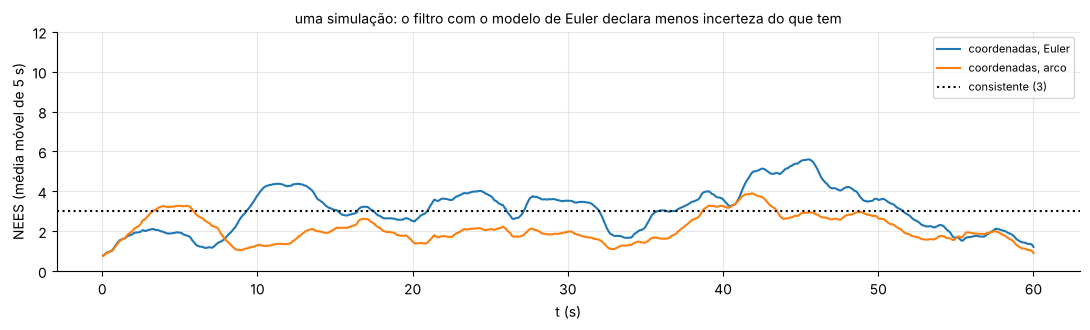

In [5]:
h_e, h_a = simula({"tipo": "coord"}, 100), simula({"tipo": "coord", "arco": True}, 100)
fig, ax = plt.subplots(figsize=(11, 3.4))
tt = np.arange(1, len(h_e["nees"]) + 1) * DT
media_movel = lambda x: np.convolve(x, np.ones(100) / 100, mode="same")
ax.plot(tt, media_movel(h_e["nees"]), label="coordenadas, Euler")
ax.plot(tt, media_movel(h_a["nees"]), label="coordenadas, arco")
ax.axhline(3, color="k", ls=":", label="consistente (3)")
ax.set_xlabel("t (s)"); ax.set_ylabel("NEES (média móvel de 5 s)"); ax.legend(fontsize=8); ax.set_ylim(0, 12)
ax.set_title("uma simulação: o filtro com o modelo de Euler declara menos incerteza do que tem", fontsize=10)
plt.tight_layout(); plt.show()

---

## 4. GPS e um Pepé desorientado: o erro certo para o sensor certo

Agora os faróis somem. Em lugar deles, uma câmera no teto vê Pepé como um ponto e dá a **posição** dele (sem a direção), com ruído de 0,3 m, a 10 Hz: um GPS. O radar continua vendo Penélope. E Pepé começa **desorientado**: a crença inicial sobre a direção do nariz tem desvio de $\sigma_{\theta,0}=1{,}5$ rad (86°). A direção só se torna observável quando ele anda: comparando o quanto andou (odometria, no corpo) com o quanto o GPS diz que ele se moveu (no mundo).

Com o GPS, o par muda: a medida $\mathbf z=p+\mathbf n$ é linear nas coordenadas e no erro do corpo (com uma rotação), mas, com o erro no mundo, depende da posição estimada $\hat p$, porque um giro em torno da origem do mundo desloca Pepé. É o contrário do que acontecia com os faróis.

In [6]:
tab_gps = monte_carlo({"coordenadas (arco), desorientado": {"tipo": "coord", "arco": True, "sensores": "gps", "sig_th0": 1.5},
                       "erro no corpo, desorientado": {"tipo": "corpo", "sensores": "gps", "sig_th0": 1.5},
                       "erro no mundo, desorientado": {"tipo": "mundo", "sensores": "gps", "sig_th0": 1.5},
                       "erro no mundo, orientado (σ = 0,1 rad)": {"tipo": "mundo", "sensores": "gps", "sig_th0": 0.1}})
tab_gps.round(3)

,perdeu o rastro,erro de posição de Pepé (cm),erro de direção de Pepé (graus),"NEES da pose, 1º segundo","NEES da pose, 60 s",erro de Penélope (m),tempo perto dela (< 1 m)
"coordenadas (arco), desorientado",0 de 20,7.590491,0.748805,3.434061,2.990661,0.219469,0.065909
"erro no corpo, desorientado",0 de 20,7.572239,0.752525,3.492261,3.023348,0.219087,0.070455
"erro no mundo, desorientado",0 de 20,7.643629,0.734581,22.246236,3.799894,0.219922,0.061364
"erro no mundo, orientado (σ = 0,1 rad)",0 de 20,7.577732,0.735371,3.556955,3.004185,0.220089,0.060455


**Leitura.**
- Depois que Pepé anda e descobre para onde está virado, os três filtros chegam à mesma precisão (7,6 cm na posição, 0,75° na direção) e perseguem Penélope igualmente bem.
- O que muda é o **começo**. Com o erro no corpo, ou nas coordenadas, o NEES do primeiro segundo é 3,5, perto do consistente. Com o erro **no mundo**, é 22: nesse período, o filtro acha que erra muito menos do que erra. A última linha confirma a causa: com a direção inicial conhecida ($\sigma_{\theta,0}=0{,}1$ rad), o mesmo filtro é consistente desde o começo (3,6). O problema é linearizar a medida do GPS, que com o erro no mundo depende de $\hat p$ e de um giro em torno da origem, quando a direção estimada está muito longe da verdadeira.
- É o resultado de Barrau e Bonnabel, visto pelo lado de quem escolhe: **o erro no mundo é invariante para medidas como as dos faróis, e o erro no corpo é invariante para medidas como as do GPS**. Com o par certo, a matriz da medida não depende da estimativa, e o filtro fica consistente mesmo começando muito longe da verdade. (O EKF nas coordenadas também se saiu bem aqui; a vantagem do filtro invariante aparece com mais força em problemas como o SLAM, exercício 4.)

---

## 5. O que levar deste notebook

1. **A pose é um número só,** e o filtro também a trata assim: a predição é $\hat q\,\mathrm{Exp}(u)$ (um arco), a correção é $\hat q\,\mathrm{Exp}(\delta\xi)$ ou $\mathrm{Exp}(\delta\xi)\,\hat q$, e a covariância é a de um erro de três números no espaço tangente.
2. **O maior erro de modelagem estava na predição, e não no tipo de erro.** Um EKF nas coordenadas com a predição pelo arco é tão bom quanto os filtros no grupo; com o passo de Euler habitual, fica otimista. O grupo ensina a fazer a predição certa.
3. **O tipo de erro deve combinar com o sensor.** Medidas de pontos conhecidos vistos do corpo (faróis) combinam com o erro no mundo; medidas da posição do corpo no mundo (GPS) combinam com o erro no corpo. Com o par certo, o jacobiano da medida não depende da estimativa, e o filtro continua consistente mesmo começando muito longe da verdade. Com o par errado, a linearização em torno de uma estimativa ruim engana o filtro, nos primeiros segundos.
4. **A não comutatividade obriga a escolher.** Nos domínios I a IV, "erro no corpo" e "erro no mundo" eram a mesma coisa. Aqui não são, e a escolha tem consequências.

**Próximo domínio:** os quaternions. A orientação sai do plano e vai para o espaço: rotações em torno de qualquer eixo, que **não comutam** entre si (nem sem translação nenhuma), e um número de quatro componentes, de módulo 1, com o mesmo duplo recobrimento do dual-complexo.

---

## 6. Exercícios

1. **Euler com passo menor.** Na seção 3, reduza o passo de 0,05 s para 0,01 s no filtro com o modelo de Euler (mantendo a simulação verdadeira com o arco). O NEES se aproxima de 3? Quanto custa isso, comparado a usar o arco?
2. **Faróis e Pepé desorientado.** Repita a seção 4 com os faróis no lugar do GPS e $\sigma_{\theta,0}=1{,}5$ rad. Qual dos três filtros fica inconsistente no começo agora?
3. **A elipse de Penélope.** Desenhe, em cada instante, a elipse de 95% da posição estimada de Penélope (o bloco $2\times2$ correspondente de $\mathbf P$). Quando ela encolhe e quando cresce?
4. **SLAM com um farol desconhecido.** Acrescente ao estado a posição de um quinto farol, desconhecida. O filtro consegue estimá-la? Com qual dos três tipos de erro o filtro fica mais consistente? (É o problema do EKF-SLAM, em que o filtro invariante tem vantagem conhecida.)
5. **O IEKF iterado.** Implemente a correção iterada (Gauss–Newton, notebook I(d)) com o erro no mundo. Ela ajuda com Pepé desorientado e o GPS?